<a href="https://colab.research.google.com/github/jangjunhyeok828/injection-molding-defect-analysis/blob/main/02_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
path = '/content/drive/MyDrive/KAMP_사출성형/'
df = pd.read_csv(path + 'cn7_shot_clean.csv', parse_dates=['TimeStamp'])
df['reason'] = df['reason'].fillna('')

df['group'] = 'Pass'
df.loc[df['reason'].str.contains('초기'), 'group'] = 'Startup_Fail'
df.loc[(df['fail'] == 1) & ~df['reason'].str.contains('초기'), 'group'] = 'Process_Fail'
print(df['group'].value_counts())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
group
Pass            1975
Process_Fail      15
Startup_Fail       5
Name: count, dtype: int64


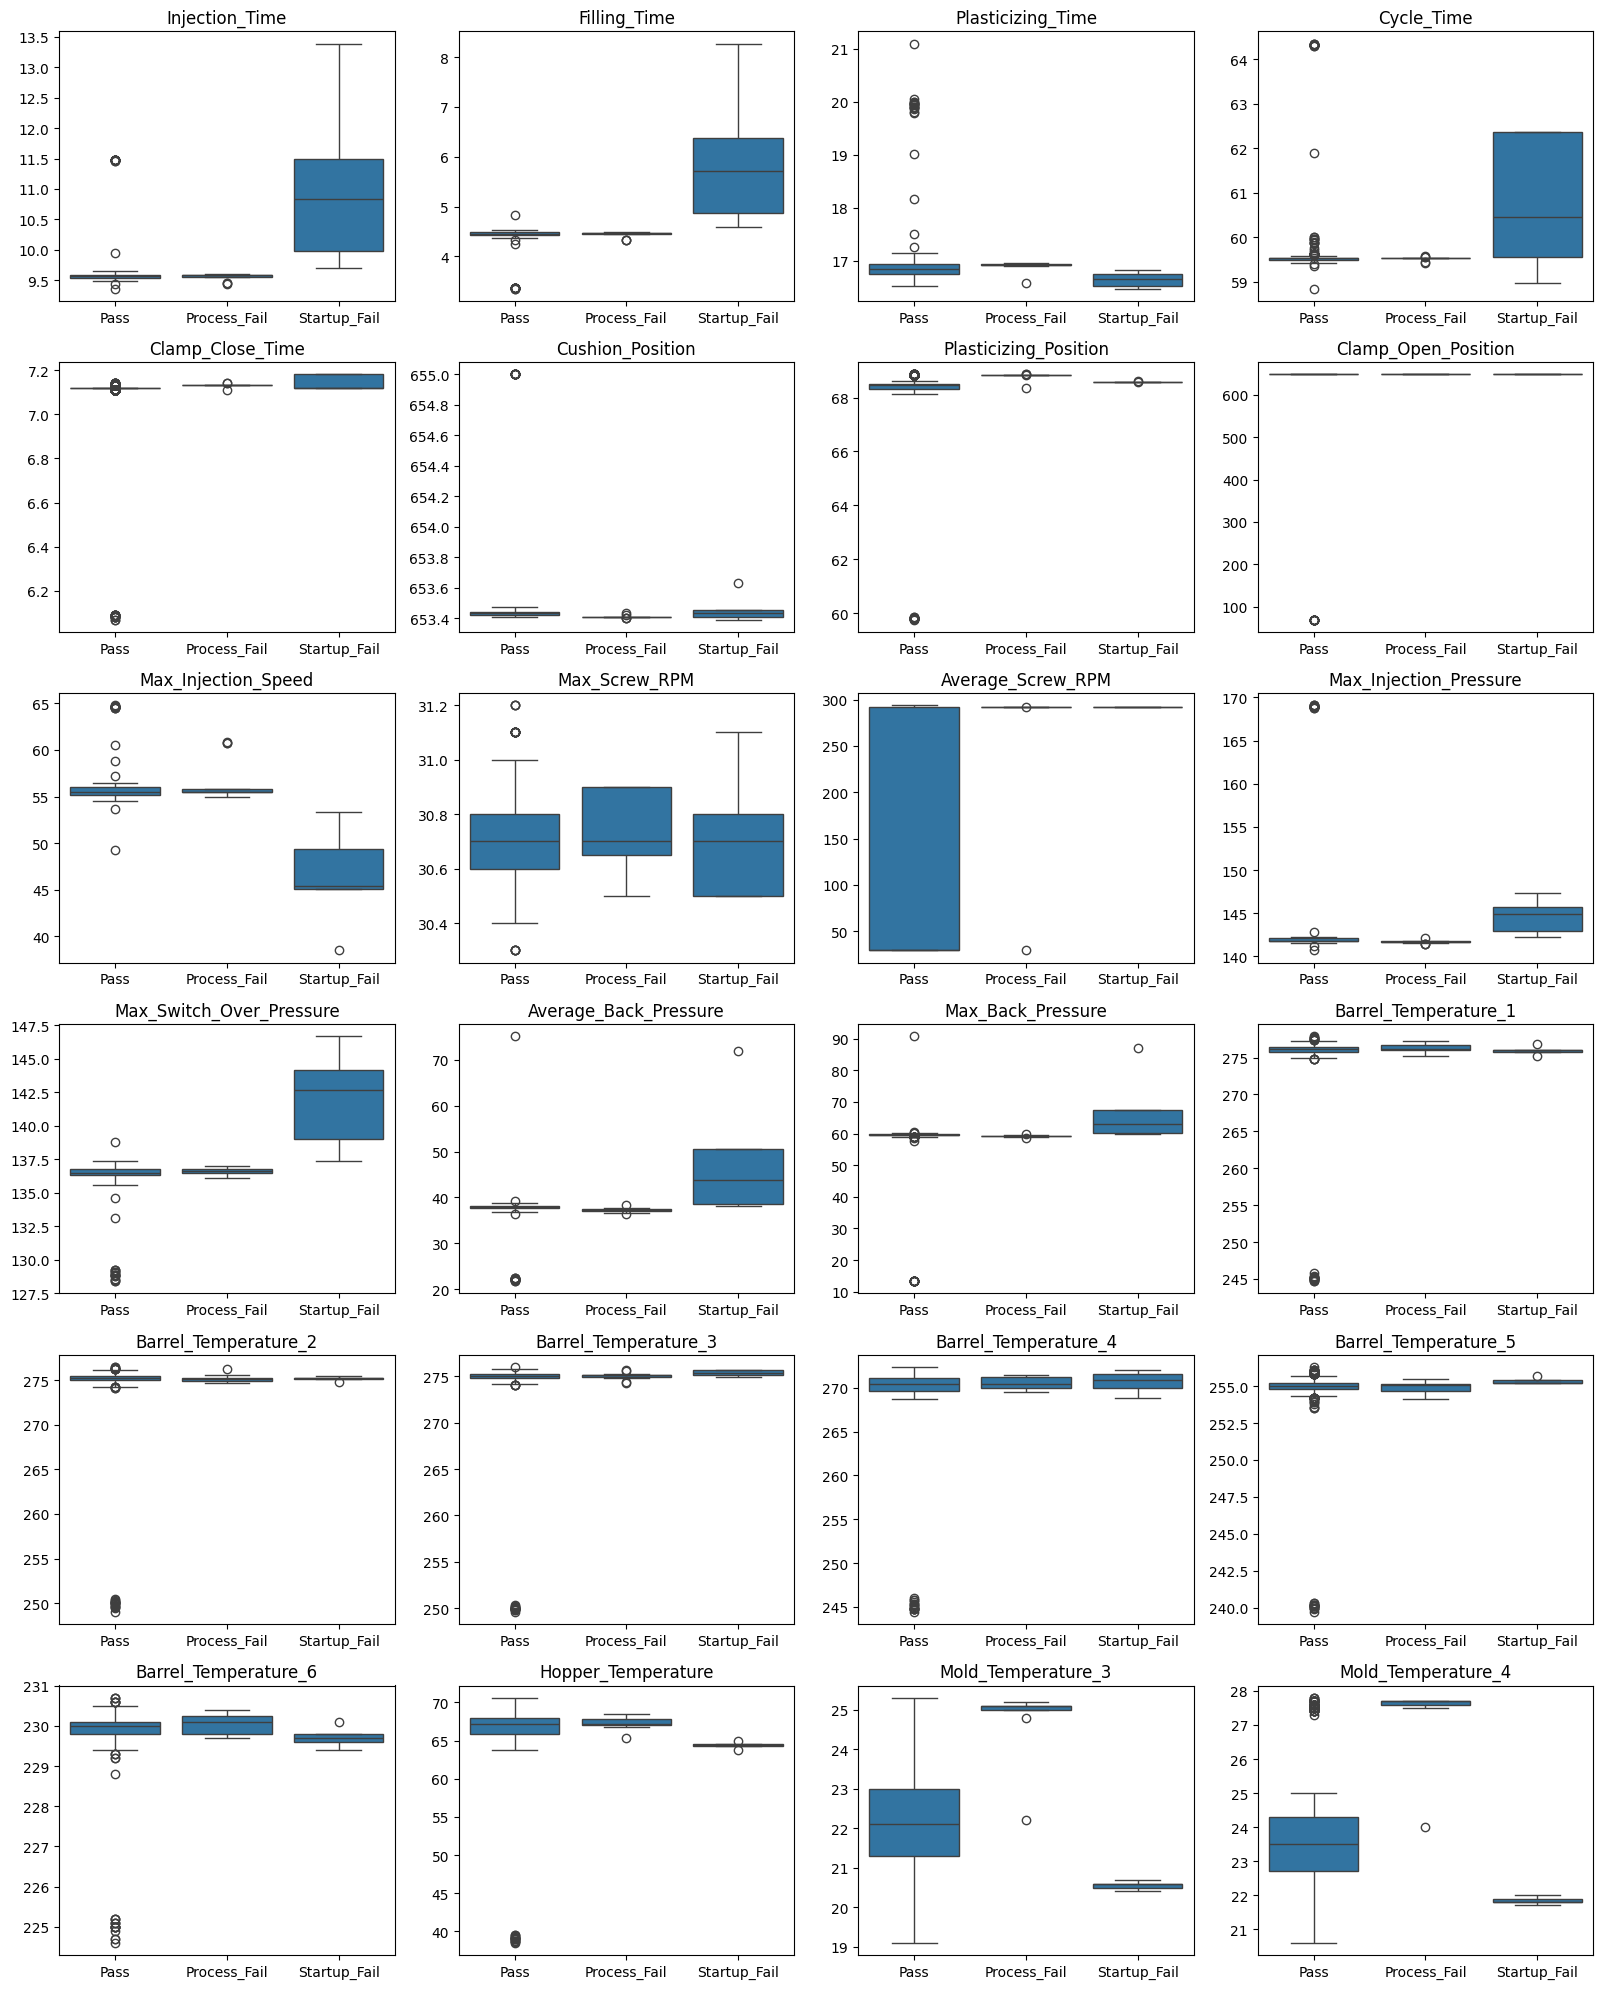

In [ ]:
feats = [c for c in df.columns if c not in ['TimeStamp', 'fail', 'reason', 'group']]
order = ['Pass', 'Process_Fail', 'Startup_Fail']

fig, axes = plt.subplots(6, 4, figsize=(16, 20))
for ax, c in zip(axes.flat, feats):
    sns.boxplot(data=df, x='group', y=c, order=order, ax=ax)
    ax.set_title(c); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

In [ ]:
df = df.sort_values('TimeStamp')
df['gap_min'] = df['TimeStamp'].diff().dt.total_seconds() / 60
display(df.groupby('group')['gap_min'].describe()[['count', 'mean', '50%', 'max']])
df[df['group'] == 'Startup_Fail'][['TimeStamp', 'gap_min']]

,count,mean,50%,max
group,,,,
Pass,1974.0,13.215620,1.00,9710.433333
Process_Fail,15.0,0.991111,1.00,1.016667
Startup_Fail,5.0,3.860000,2.65,9.966667


,TimeStamp,gap_min
632,2020-10-27 00:56:21,9.966667
633,2020-10-27 00:59:00,2.650000
634,2020-10-27 01:03:34,4.566667
635,2020-10-27 01:04:41,1.116667
636,2020-10-27 01:05:41,1.000000


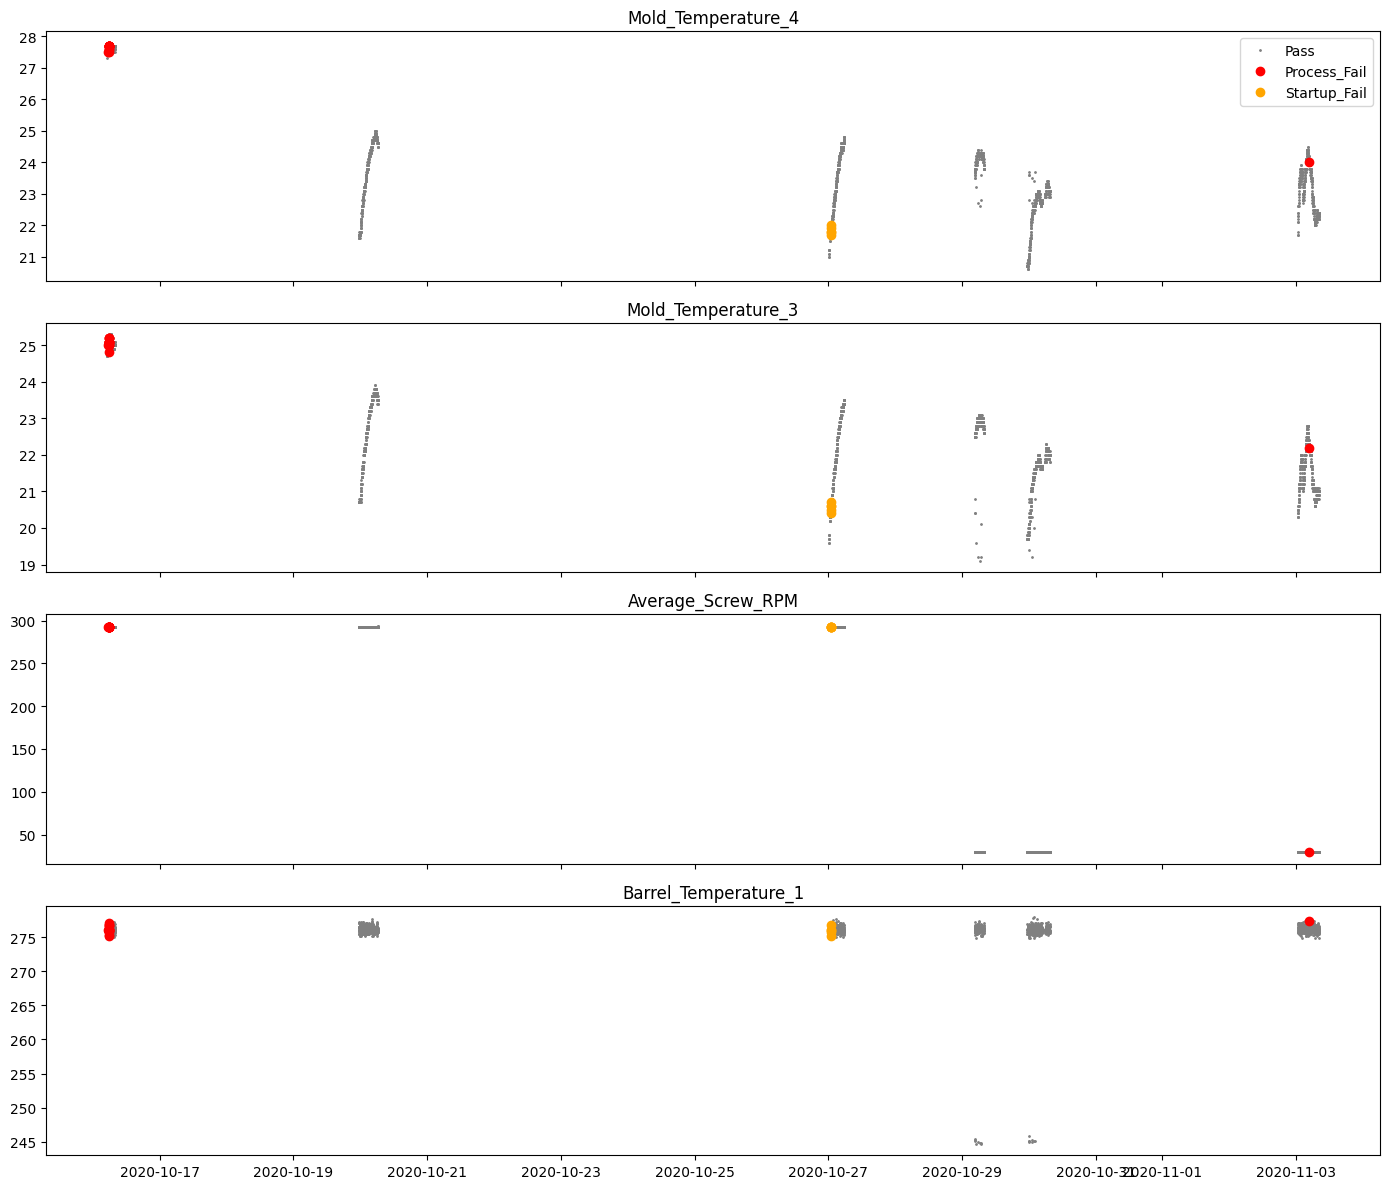

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
for ax, c in zip(axes, ['Mold_Temperature_4', 'Mold_Temperature_3', 'Average_Screw_RPM', 'Barrel_Temperature_1']):
    ax.plot(df['TimeStamp'], df[c], '.', ms=2, color='gray', label='Pass')
    for g, col in [('Process_Fail', 'red'), ('Startup_Fail', 'orange')]:
        s = df[df['group'] == g]
        ax.plot(s['TimeStamp'], s[c], 'o', color=col, label=g)
    ax.set_title(c)
axes[0].legend(); plt.tight_layout(); plt.show()

In [ ]:
df.groupby(df['TimeStamp'].dt.date).agg(
    shots=('fail', 'size'), fails=('fail', 'sum'),
    mold3=('Mold_Temperature_3', 'mean'), mold4=('Mold_Temperature_4', 'mean'))

,shots,fails,mold3,mold4
TimeStamp,,,,
2020-10-16,188,14,25.023404,27.613298
2020-10-19,36,0,20.708334,21.697223
2020-10-20,382,0,22.808639,23.890052
2020-10-27,314,5,22.123885,23.402866
2020-10-29,230,0,22.305217,23.602174
2020-10-30,382,0,21.515969,22.662565
2020-11-03,463,1,21.505616,23.180777


In [ ]:
df[df['group'] == 'Process_Fail'][['TimeStamp', 'reason', 'Mold_Temperature_3', 'Mold_Temperature_4']]

,TimeStamp,reason,Mold_Temperature_3,Mold_Temperature_4
24,2020-10-16 05:21:38,가스,25.000000,27.500000
40,2020-10-16 05:37:29,가스,25.200001,27.700001
48,2020-10-16 05:45:26,가스,25.200001,27.700001
50,2020-10-16 05:47:24,가스,25.100000,27.700001
51,2020-10-16 05:48:24,가스,25.200001,27.700001
52,2020-10-16 05:49:24,가스,25.100000,27.700001
53,2020-10-16 05:50:25,가스,25.100000,27.700001
54,2020-10-16 05:51:23,가스,25.000000,27.600000
55,2020-10-16 05:52:23,가스,24.799999,27.500000
56,2020-10-16 05:53:23,가스,25.000000,27.700001


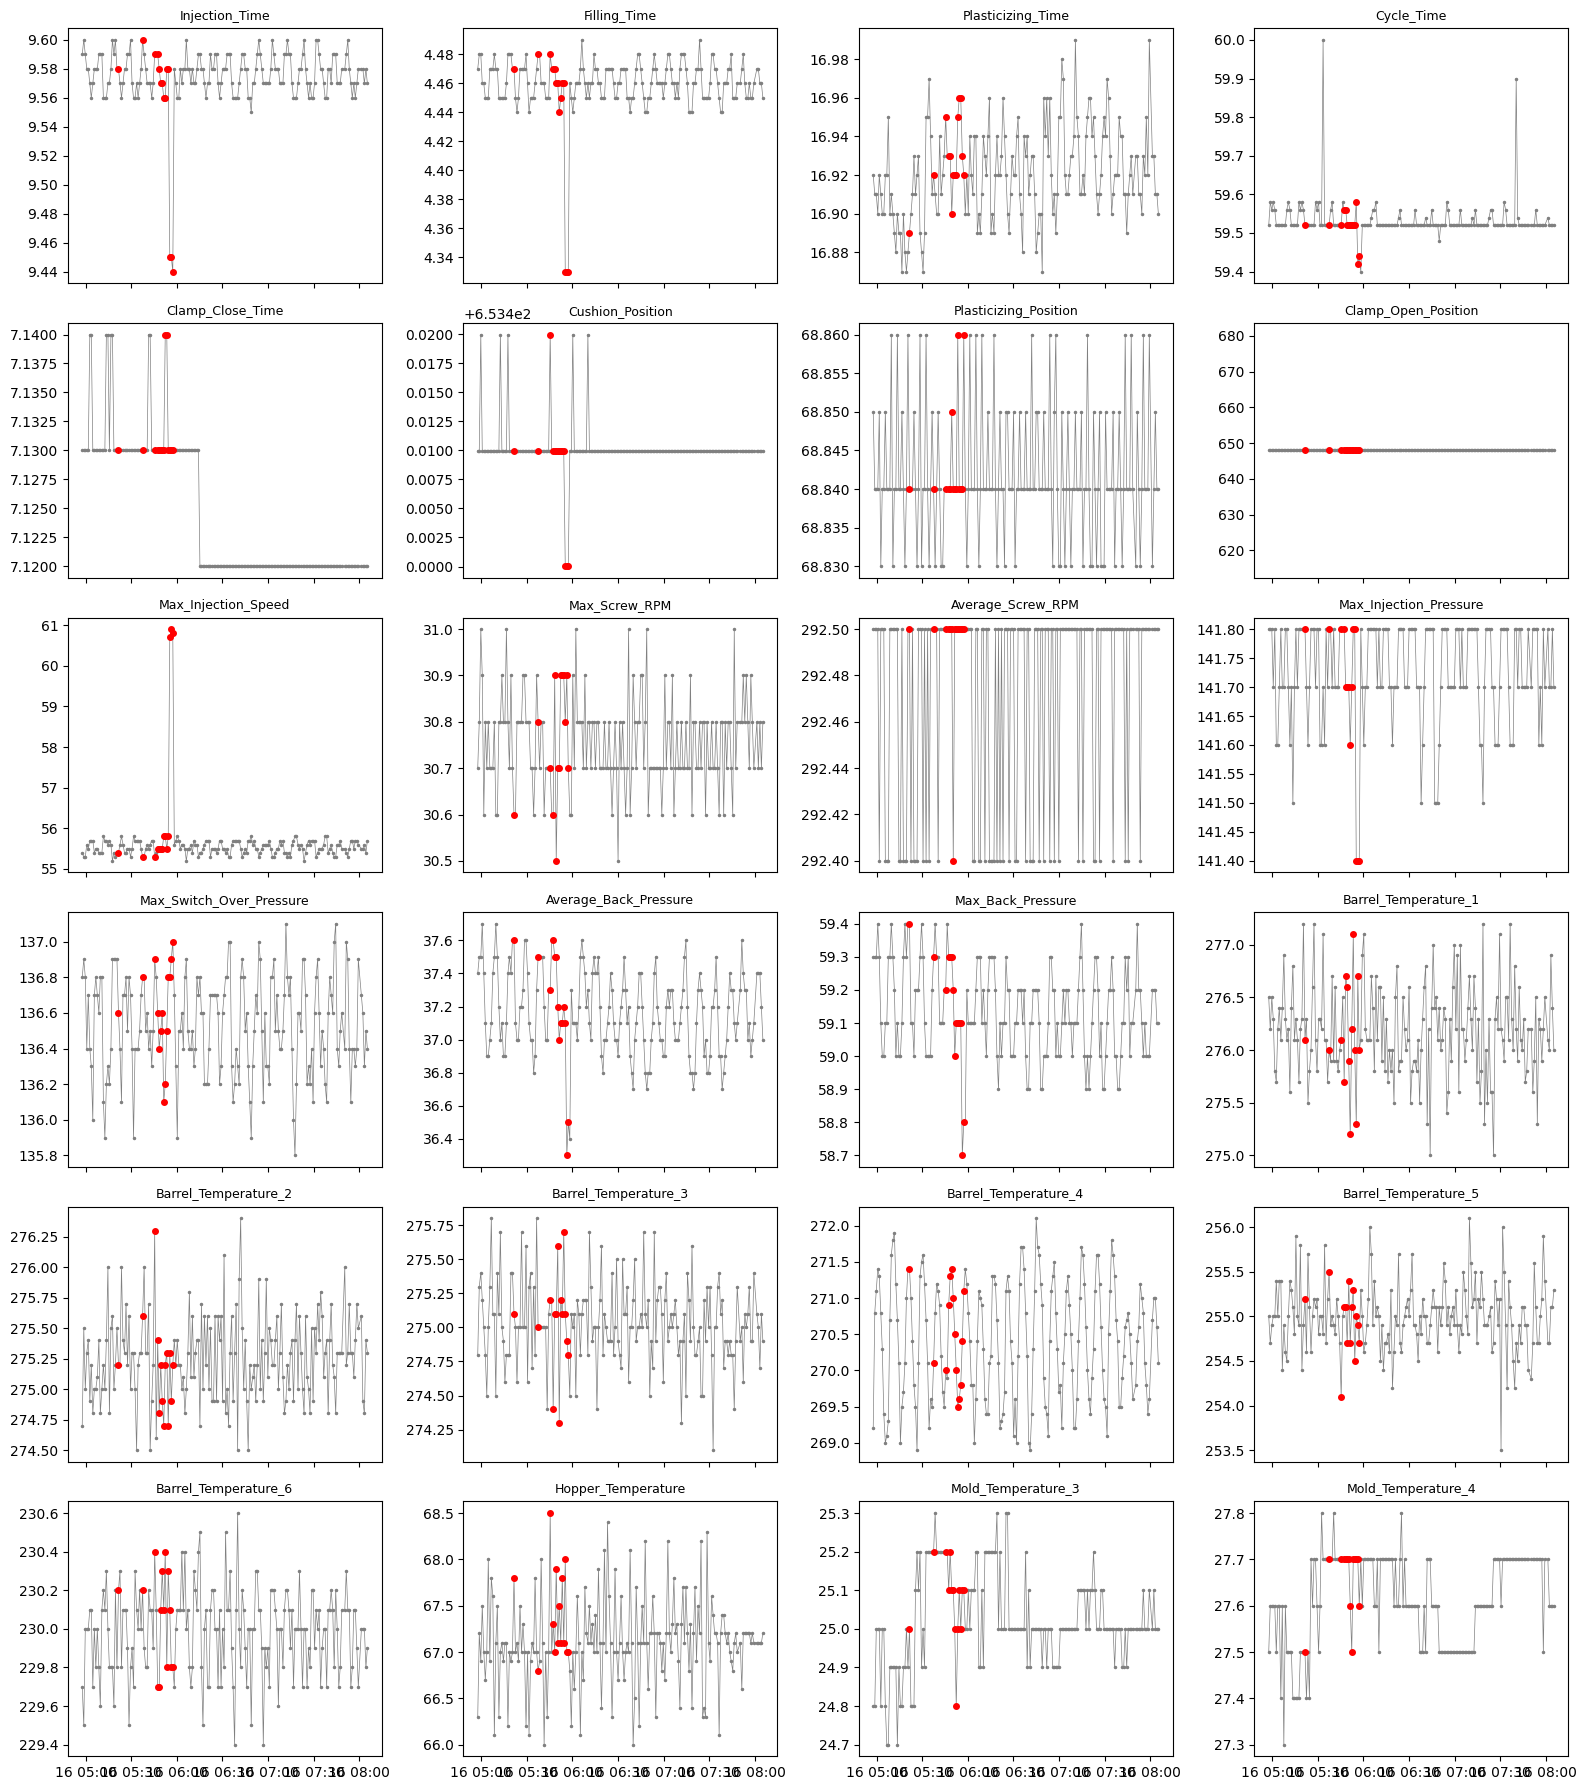

In [ ]:
import numpy as np
d16 = df[df['TimeStamp'].dt.date == pd.Timestamp('2020-10-16').date()].copy()

fig, axes = plt.subplots(6, 4, figsize=(16, 18), sharex=True)
for ax, c in zip(axes.flat, feats):
    ax.plot(d16['TimeStamp'], d16[c], '.-', ms=3, lw=0.5, color='gray')
    s = d16[d16['fail'] == 1]
    ax.plot(s['TimeStamp'], s[c], 'o', color='red', ms=4)
    ax.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
start, end = pd.Timestamp('2020-10-16 05:21'), pd.Timestamp('2020-10-16 05:58')
d16['phase'] = np.where(d16['TimeStamp'] < start, '1_before',
               np.where(d16['TimeStamp'] <= end, '2_burst', '3_after'))
print(d16.groupby('phase')['fail'].agg(['size', 'sum']))
d16.groupby('phase')[feats].mean().T

          size  sum
phase              
1_before    24    0
2_burst     37   14
3_after    127    0


phase,1_before,2_burst,3_after
Injection_Time,9.580000,9.565135,9.576772
Filling_Time,4.464583,4.450000,4.460945
Plasticizing_Time,16.900833,16.921351,16.924488
Cycle_Time,59.542501,59.540541,59.528032
Clamp_Close_Time,7.132500,7.131081,7.121338
Cushion_Position,653.411224,653.409437,653.410131
Plasticizing_Position,68.842915,68.841620,68.841888
Clamp_Open_Position,647.989990,647.989990,647.989990
Max_Injection_Speed,55.508334,55.981081,55.540157
Max_Screw_RPM,30.775000,30.751351,30.751181


In [ ]:
d16['gap_min'] = d16['TimeStamp'].diff().dt.total_seconds() / 60
d16[(d16['TimeStamp'] >= '2020-10-16 05:15') & (d16['TimeStamp'] <= '2020-10-16 06:20')][
    ['TimeStamp', 'gap_min', 'fail', 'reason', 'Max_Injection_Speed', 'Clamp_Close_Time']]

,TimeStamp,gap_min,fail,reason,Max_Injection_Speed,Clamp_Close_Time
18,2020-10-16 05:15:39,0.966667,0,,55.700001,7.13
19,2020-10-16 05:16:39,1.000000,0,,55.599998,7.14
20,2020-10-16 05:17:39,1.000000,0,,55.200001,7.14
21,2020-10-16 05:18:37,0.966667,0,,55.400002,7.13
22,2020-10-16 05:19:37,1.000000,0,,55.299999,7.13
...,...,...,...,...,...,...
78,2020-10-16 06:15:11,0.966667,0,,55.400002,7.12
79,2020-10-16 06:16:11,1.000000,0,,55.400002,7.12
80,2020-10-16 06:17:11,1.000000,0,,55.500000,7.12
81,2020-10-16 06:18:09,0.966667,0,,55.599998,7.12


In [ ]:
raw = pd.read_csv(path + 'labeled_data.csv').drop_duplicates()
raw['TimeStamp'] = pd.to_datetime(raw['TimeStamp'])
b = raw[raw['PART_NAME'].str.contains('CN7') & (raw['PassOrFail'] == 'N')]
pd.crosstab(b['TimeStamp'].dt.date, [b['PART_NAME'].str[-2:], b['Reason']])

PART_NAME  LH             RH           
Reason     가스 미성형 초기허용불량  가스 미성형 초기허용불량
TimeStamp                              
2020-10-16  3   1      0  10   3      0
2020-10-27  0   0      5   0   0      5
2020-11-03  0   1      0   0   0      0

In [ ]:
w = d16[(d16['TimeStamp'] >= '2020-10-16 05:15') & (d16['TimeStamp'] <= '2020-10-16 06:20')]
print('불량 구간 앞뒤 최대 간격(분):', w['gap_min'].max())
print('10/16 하루 최대 간격(분):', d16['gap_min'].max())
d16[d16['gap_min'] > 1.5][['TimeStamp', 'gap_min', 'fail', 'reason']]

불량 구간 앞뒤 최대 간격(분): 1.0166666666666666
10/16 하루 최대 간격(분): 2.0166666666666666


,TimeStamp,gap_min,fail,reason
173,2020-10-16 07:50:26,1.983333,0,
183,2020-10-16 08:01:22,2.016667,0,
